# Separating cell-boundary from cytoplasmic RNA distributions

Neither a cell-boundary nor a purely cytoplasmic distribution is part of the simulation suite
the model was trained on, so both were simulated and embedded with the published model:

* **cell-boundary**: 90 % of transcripts in a narrow rim just inside the cell outline, the rest
  spread through the cytoplasm;
* **cytoplasmic**: transcripts uniform throughout the cell but excluded from the nucleus.

In the data these are keyed `celledge` and `cytoplasm`. Cell-boundary is distinct from the
paper's existing `cell-edge` class.

Added alongside the six original patterns, a random forest reading only the 15-dimensional
latent, with folds grouped by cell so no cell appears on both sides of a split, recovers them
at F1 **0.83** (cell-boundary) and **0.77** (cytoplasmic), at an eight-class kappa of **0.76**
(§2). The two occupy their own region of the latent space, are confused mainly with each
other and with `pericellular`, and no cytoplasmic observation is assigned to `random`. The
distinction is kept in the embedding without the cell-boundary mask as an input.

These are clean simulated examples of each pattern: they show what the embedding can resolve,
not performance on real data. The page at the end reproduces Supp. Fig. 7.

In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from skimage import io as skio

import paths
from palette import pattern_palette

DATA = paths.data("cell_boundary")
EXAMPLES = DATA / "examples"
FIG = paths.figures("cell_boundary")

EXIST = ["cell-edge","extranuclear","intranuclear","pericellular","perinuclear","random"]
NEWP  = ["celledge","cytoplasm"]
NAME  = {"celledge": "cell-boundary", "cytoplasm": "cytoplasmic"}   # data key -> display name
disp  = lambda p: NAME.get(p, p)
COL = pattern_palette()          # the paper's colours, plus the two additional patterns
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
mpl.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,
    "savefig.facecolor":SURFACE,"text.color":INK,"axes.labelcolor":INK_MUTED,
    "xtick.color":INK_MUTED,"ytick.color":INK_MUTED,"axes.edgecolor":GRID,
    "font.size":9,"axes.titlesize":10,"figure.dpi":120,
    "axes.spines.top":False,"axes.spines.right":False,"legend.frameon":False})

# Latents of the 44,706 held-out simulated observations (six original patterns) and of the
# two additional patterns, all encoded with the published model (mode="mu").
# Produced by scripts/cell_boundary/step3_separation.py, which needs a GPU.
z = np.load(DATA / "combined.npz", allow_pickle=True)
X = z["X"].astype(np.float64)
pattern = z["pattern"].astype(str)
cell = z["cell_id"].astype(str)
print(f"{X.shape[0]:,} observations | "
      + " ".join(f"{p} {int((pattern==p).sum()):,}" for p in NEWP + EXIST))

57,439 observations | celledge 6,363 cytoplasm 6,370 cell-edge 6,441 extranuclear 6,337 intranuclear 6,364 pericellular 6,442 perinuclear 6,398 random 12,724


## 1. The two patterns

* **cytoplasmic** (`cytoplasm`): spots spread uniformly through the cell, excluding the nucleus.
* **cell-boundary** (`celledge`): 90 % of spots in a narrow rim just inside the cell boundary,
  the remaining 10 % spread through the cytoplasm. The background is the cytoplasmic
  distribution, so the two differ *only* in boundary enrichment, and 90 % rather than a pure
  rim keeps the pattern no more explicit than the existing classes.

Both were simulated on the same 64 held-out cells the published model never trained on, by
`scripts/cell_boundary/simulate_cytoplasm.py`.

**`pericellular`** is shown beside them for reference. It is one of the six patterns the model
was trained on, and in the embedding it falls between the two additional categories, confused
about equally with each (§2). The two are therefore told apart across a region of the latent
space the model already populates, not in an empty corner of it.

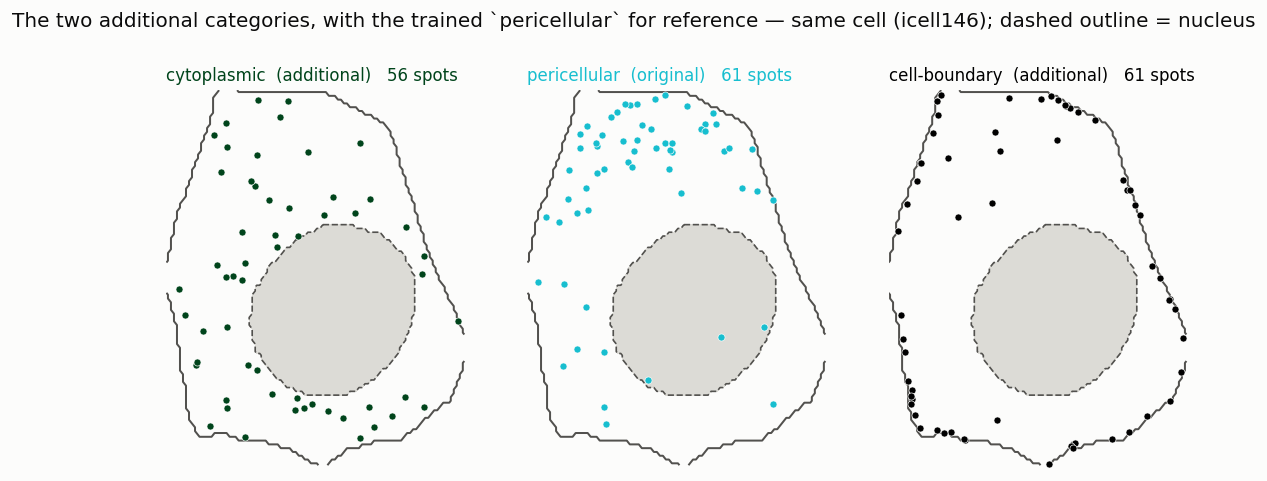

In [2]:
# uniform -> graded peripheral -> hard rim
TRIO = ["cytoplasm", "pericellular", "celledge"]
TARGET = 60      # transcripts per example; the simulation closest to it is drawn

def coords_file(pat, cell_id):
    """The example simulation of `pat` in `cell_id` whose transcript count is closest to TARGET.
    Coordinates are unrotated, matching the unrotated cell and nucleus masks they are drawn on."""
    c = list((EXAMPLES / "gene_coords").glob(f"{pat}_*spots_icell{cell_id}_*_coords.csv"))
    assert c, (pat, cell_id)
    return sorted(c, key=lambda q: (abs(int(re.search(r"_(\d+)spots", q.name).group(1)) - TARGET), q.name))[0]

def masks(cell_id):
    cellm = skio.imread(EXAMPLES / "cell_filtered" / f"random_icell{cell_id}_cell.tif") > 0
    nuc   = skio.imread(EXAMPLES / "nuclei_filtered" / f"random_icell{cell_id}_dapi.tif") > 0
    return cellm, nuc

def panel_fig(cell_id="146"):
    cellm, nuc = masks(cell_id)
    fig, axes = plt.subplots(1, 3, figsize=(11.0, 4.1))
    for ax, pat in zip(axes, TRIO):
        c = pd.read_csv(coords_file(pat, cell_id))
        ax.contour(cellm, levels=[0.5], colors=[INK_MUTED], linewidths=1.2)
        ax.contourf(nuc, levels=[0.5,1.5], colors=["#dcdbd6"])
        ax.contour(nuc, levels=[0.5], colors=[INK_MUTED], linewidths=1.0, linestyles="--")
        ax.scatter(c["col"], c["row"], s=18, c=COL[pat], edgecolors=SURFACE,
                   linewidths=0.4, zorder=3)
        tag = "  (additional)" if pat in NEWP else "  (original)"
        ax.set_title(f"{disp(pat)}{tag}   {len(c)} spots", loc="left", fontsize=10, color=COL[pat])
        ax.set_xlim(0,100); ax.set_ylim(100,0); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
    fig.suptitle(f"The two additional categories, with the trained `pericellular` for reference "
                 f"\u2014 same cell (icell{cell_id}); dashed outline = nucleus",
                 x=0.008, ha="left", fontsize=12, color=INK, y=1.04)
    fig.savefig(FIG/"fig1_patterns.png", bbox_inches="tight", dpi=170)
panel_fig(); plt.show()

## 2. Where they land, and what they get confused with

A random forest reading only the 15 latent dimensions, five-fold cross-validated and
**grouped by cell**, three repeats, over all eight classes shows whether the additional
categories carve out their own region or get absorbed into an existing one, and in particular
whether the cytoplasmic class is confused with `random`.

The probe result is read from the cached run in `eightclass_raw.csv`; `run_probe()` below is
the code that produced it and runs only if that file is missing.

Panels **c–e** are the same embedding three times, once per pattern along the
uniform → graded-peripheral → hard-rim axis. In each, the focal pattern is drawn at full
strength in its own colour and every other observation is greyed back, so the three regions
can be compared directly rather than picked out of one crowded plot.

In [3]:
def run_probe():
    from revbench.metrics.probe import rf_probe
    d = pd.DataFrame([x.as_dict() for x in rf_probe(
        X, pattern, groups=cell, cv_scheme="stratified_group", n_repeats=3,
        target="pattern8", confusion=True)])
    d.to_csv(DATA / "eightclass_raw.csv", index=False)
    return d

d = (pd.read_csv(DATA / "eightclass_raw.csv", keep_default_na=False)
     if (DATA / "eightclass_raw.csv").exists() else run_probe())
k = d.loc[d["metric"] == "kappa", "value"].astype(float)
print(f"8-class kappa {k.mean():.4f} ± {k.std():.4f}   (six original classes alone: 0.7756)\n")
print("per-class F1:")
print(d[(d["metric"]=="f1") & d["class_label"].ne("")].groupby("class_label")["value"]
      .mean().sort_values(ascending=False).to_string(float_format=lambda v: f"{v:.4f}"))
cm = d[d["metric"]=="confusion_count"].copy()
cm[["true","pred"]] = cm["class_label"].str.split("|", expand=True)
conf = cm.pivot_table(index="true", columns="pred", values="value", aggfunc="sum").fillna(0)
conf = conf.div(conf.sum(1), axis=0).reindex(index=NEWP+EXIST, columns=NEWP+EXIST)

8-class kappa 0.7601 ± 0.0114   (six original classes alone: 0.7756)

per-class F1:
class_label
intranuclear   0.9938
random         0.8692
celledge       0.8283
perinuclear    0.8087
pericellular   0.7900
cytoplasm      0.7717
cell-edge      0.6139
extranuclear   0.5729


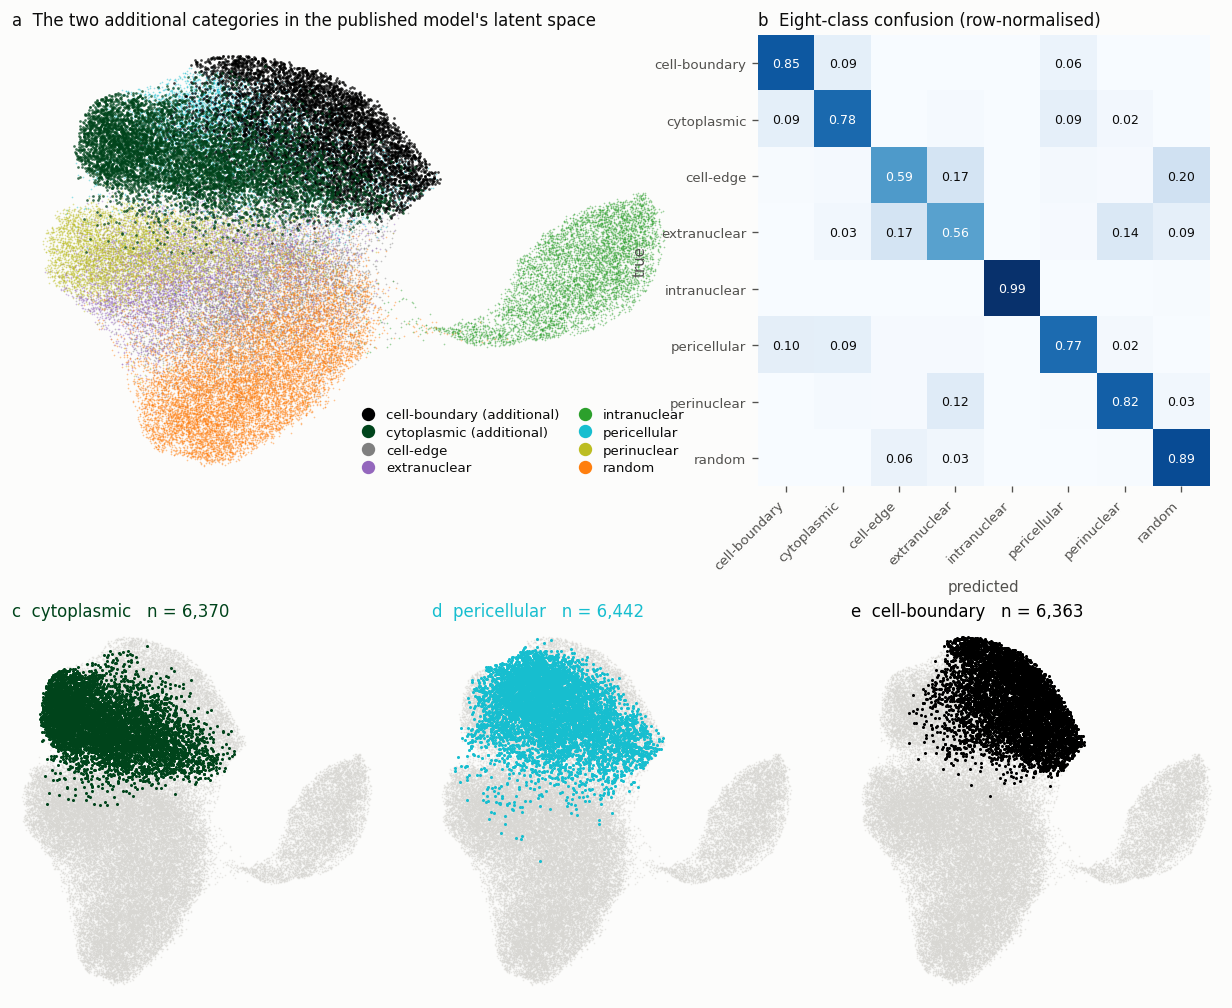

In [4]:
def umap_embedding():
    """2-D UMAP of the latent, for display only. Cached, because UMAP is stochastic and the
    page must show the same layout as the published figure."""
    cache = DATA / "umap.npy"
    if cache.exists():
        return np.load(cache)
    import anndata as ad, scanpy as sc
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        a = ad.AnnData(X.astype(np.float32))
        sc.pp.neighbors(a, n_neighbors=25, use_rep="X"); sc.tl.umap(a)
    np.save(cache, a.obsm["X_umap"])
    return a.obsm["X_umap"]

emb = umap_embedding()
assert len(emb) == len(pattern)

def fig_landing():
    order = np.random.RandomState(101).permutation(len(emb))

    fig = plt.figure(figsize=(13.0, 10.4))
    gs = fig.add_gridspec(2, 12, height_ratios=[1.0, 0.82], hspace=0.34, wspace=0.9)

    ax = fig.add_subplot(gs[0, 0:7])
    for p in EXIST:
        mm = pattern[order] == p
        ax.scatter(*emb[order][mm].T, s=1.0, c=COL[p], alpha=0.45, linewidths=0, rasterized=True)
    for p in NEWP:
        mm = pattern[order] == p
        ax.scatter(*emb[order][mm].T, s=2.6, c=COL[p], alpha=0.75, linewidths=0, rasterized=True)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title("a  The two additional categories in the published model's latent space",
                 loc="left", color=INK)
    ax.legend(handles=[Line2D([],[],marker="o",ls="",markersize=7,color=COL[p],
                              label=disp(p)+(" (additional)" if p in NEWP else "")) for p in NEWP+EXIST],
              loc="lower right", ncol=2, fontsize=8, labelspacing=0.35,
              columnspacing=0.9, handletextpad=0.35)

    ax = fig.add_subplot(gs[0, 7:12])
    ax.imshow(conf.values, cmap="Blues", vmin=0, vmax=1)
    lab = [disp(p) for p in conf.index]
    ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab, fontsize=8)
    for i in range(len(lab)):
        for j in range(len(lab)):
            v = conf.values[i,j]
            if v >= 0.02:
                ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7.5,
                        color="#ffffff" if v>0.55 else INK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title("b  Eight-class confusion (row-normalised)", loc="left", color=INK)
    for s in ax.spines.values(): s.set_visible(False)

    # One panel per pattern: the focal class at full opacity in its own colour over
    # every other observation in grey. Shared axis limits and the one embedding, so
    # a difference between the panels is a difference in where the class sits and
    # nothing else.
    pad = 0.6
    xl = (emb[:,0].min()-pad, emb[:,0].max()+pad)
    yl = (emb[:,1].min()-pad, emb[:,1].max()+pad)
    for k, pat in enumerate(TRIO):
        ax = fig.add_subplot(gs[1, 4*k:4*(k+1)])
        mm = pattern[order] == pat
        ax.scatter(*emb[order][~mm].T, s=0.9, c="#d8d7d3", alpha=0.55,
                   linewidths=0, rasterized=True)
        ax.scatter(*emb[order][mm].T, s=3.4, c=COL[pat], alpha=1.0,
                   linewidths=0, rasterized=True)
        ax.set_xlim(*xl); ax.set_ylim(*yl)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_title(f"{'cde'[k]}  {disp(pat)}   n = {int((pattern==pat).sum()):,}",
                     loc="left", color=COL[pat], fontsize=10)
    fig.savefig(FIG/"fig2_landing.png", bbox_inches="tight", dpi=170)
fig_landing(); plt.show()

## In short

The embedding keeps the distinction. Boundary-enriched and uniformly cytoplasmic RNAs are
recovered at F1 0.83 and 0.77 among eight classes with folds grouped by cell, they hold their
own region of the latent space alongside the six original patterns, and the cytoplasmic class
is not collapsed onto `random`, so "uniform in the cytoplasm" and "uniform throughout the
cell" remain distinct. None of this requires the cell-boundary mask as a model input.

## Supp. Fig. 7

The published page, drawn from the same cached latents, UMAP and probe results as above.

wrote 7_cell_boundary_vs_cytoplasmic_total.svg / .png
{'k8': 0.7601, 'f1_cell_boundary': 0.8283, 'f1_cytoplasmic': 0.7717, 'cytoplasmic_to_random': 0.0}


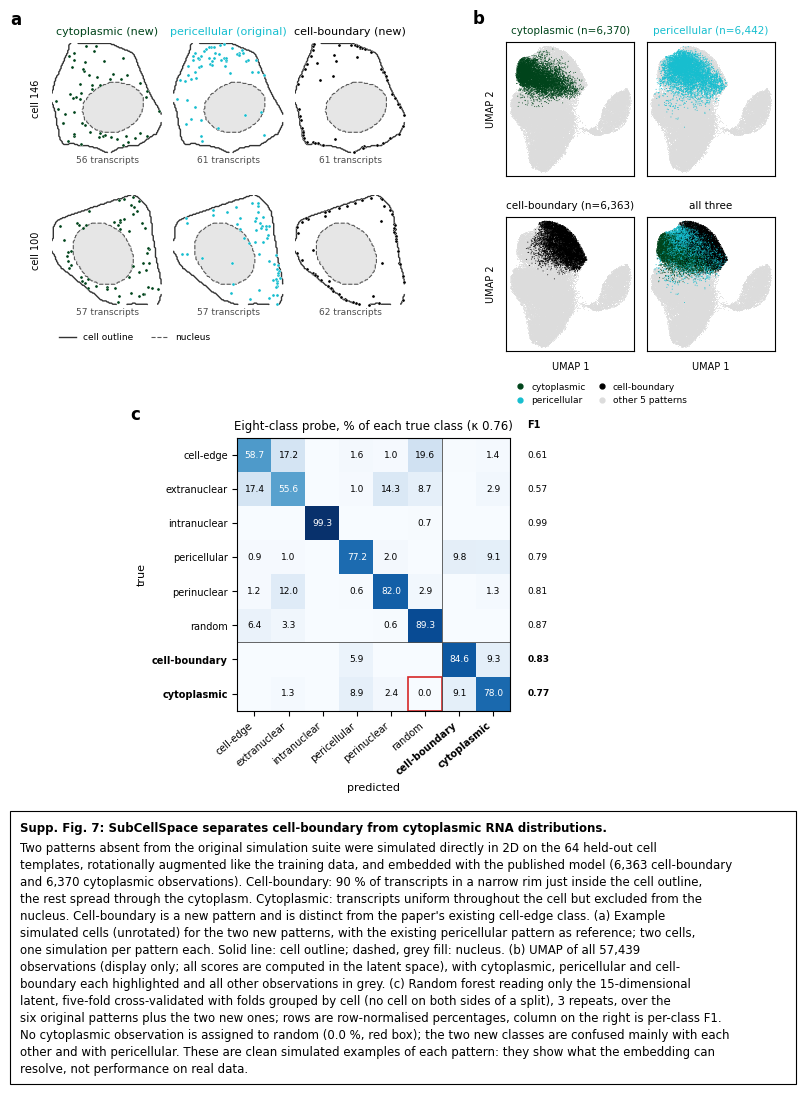

In [5]:
from matplotlib.patches import Rectangle
from supp_style import new_page, panel_letter, caption_box, save_page, COL

ORDER = EXIST + NEWP
n_new = {p: int((pattern == p).sum()) for p in NEWP}
assert n_new == {"celledge": 6363, "cytoplasm": 6370}
assert len(np.unique(cell[np.isin(pattern, NEWP)])) == 64

f1 = d[(d.metric == "f1") & d.class_label.ne("")].groupby("class_label")["value"].mean()
k8 = d.loc[d.metric == "kappa", "value"].astype(float)
page_conf = pd.read_csv(DATA / "confusion_row_normalised.csv", index_col=0).reindex(index=ORDER, columns=ORDER)
# the cached normalised table must agree with the raw counts used above
assert np.allclose(conf.reindex(index=ORDER, columns=ORDER).values, page_conf.values)

fig = new_page()

# ---------------------------------------------------------------- a: example cells
CELLS = ["146", "100"]
axes_a = []
w, h, x0, y0 = 0.135, 0.095, 0.075, 0.862
GAP = 0.035
for r, cid in enumerate(CELLS):
    cellm, nuc = masks(cid)
    for k, pat in enumerate(TRIO):
        ax = fig.add_axes([x0 + k * (w + 0.012), y0 - r * (h + GAP), w, h])
        c = pd.read_csv(coords_file(pat, cid))
        ax.contourf(nuc, levels=[0.5, 1.5], colors=["#e6e6e6"])
        ax.contour(nuc, levels=[0.5], colors=["0.35"], linewidths=0.8, linestyles="--")
        ax.contour(cellm, levels=[0.5], colors=["0.2"], linewidths=1.0)
        ax.scatter(c["col"], c["row"], s=5, c=COL[pat], edgecolors="white", linewidths=0.25, zorder=3)
        ax.set_xlim(0, 100); ax.set_ylim(100, 0); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        ax.text(0.5, -0.02, f"{len(c)} transcripts", transform=ax.transAxes, ha="center", va="top", fontsize=6.5, color="0.3")
        if r == 0:
            tag = "new" if pat in NEWP else "original"
            ax.set_title(f"{disp(pat)} ({tag})", fontsize=8, color=COL[pat])
        if k == 0:
            ax.set_ylabel(f"cell {cid}", fontsize=7)
        axes_a.append(ax)
panel_letter(fig, axes_a[0], "a", dx=-0.05)
fig.legend(handles=[Line2D([], [], color="0.2", lw=1.0, label="cell outline"),
                    Line2D([], [], color="0.35", lw=0.8, ls="--", label="nucleus")],
           loc="upper left", bbox_to_anchor=(x0, y0 - (h + GAP) - 0.016), ncol=2,
           frameon=False, fontsize=6.5, handlelength=1.8)

# ---------------------------------------------------------------- b: focal embeddings
order = np.random.RandomState(101).permutation(len(emb))
E, P = emb[order], pattern[order]
pad = 0.6
xl = (emb[:, 0].min() - pad, emb[:, 0].max() + pad)
yl = (emb[:, 1].min() - pad, emb[:, 1].max() + pad)
panels = [[p] for p in TRIO] + [TRIO]
axes_d = []
for k, foc in enumerate(panels):
    ax = fig.add_axes([0.625 + (k % 2) * 0.17, 0.843 - (k // 2) * 0.15, 0.155, 0.115])
    mm = np.isin(P, foc)
    ax.scatter(*E[~mm].T, s=0.25, c="#dcdcdc", linewidths=0, rasterized=True)
    ax.scatter(*E[mm].T, s=0.5, c=[COL[p] for p in P[mm]], linewidths=0, rasterized=True)
    ax.set_xlim(*xl); ax.set_ylim(*yl)
    ax.set_xticks([]); ax.set_yticks([])
    if len(foc) == 1:
        ax.set_title(f"{disp(foc[0])} (n={int((pattern == foc[0]).sum()):,})", fontsize=7.5, color=COL[foc[0]])
    else:
        ax.set_title("all three", fontsize=7.5)
    if k % 2 == 0: ax.set_ylabel("UMAP 2", fontsize=7)
    if k // 2 == 1: ax.set_xlabel("UMAP 1", fontsize=7)
    axes_d.append(ax)
ax_d4 = axes_d[3]
ax_d4.legend(handles=[Line2D([], [], marker="o", ls="", ms=3.5, color=COL[p], label=disp(p)) for p in TRIO]
             + [Line2D([], [], marker="o", ls="", ms=3.5, color="#dcdcdc", label="other 5 patterns")],
             loc="upper left", bbox_to_anchor=(-1.12, -0.17), ncol=2, frameon=False, fontsize=6.5,
             handletextpad=0.2, columnspacing=0.8)
panel_letter(fig, axes_d[0], "b", dx=-0.04)

# ---------------------------------------------------------------- c: 8-class confusion
ax_c = fig.add_axes([0.30, 0.38, 0.33, 0.245])
V = page_conf.values * 100
ax_c.imshow(V, cmap="Blues", vmin=0, vmax=100)
labels = [disp(p) for p in ORDER]
ax_c.set_xticks(range(8)); ax_c.set_xticklabels(labels, rotation=40, ha="right")
ax_c.set_yticks(range(8)); ax_c.set_yticklabels(labels)
for t in ax_c.get_xticklabels() + ax_c.get_yticklabels():
    if t.get_text() in NAME.values():
        t.set_fontweight("bold")
ir, jr = ORDER.index("cytoplasm"), ORDER.index("random")
for i in range(8):
    for j in range(8):
        v = V[i, j]
        if v >= 0.5 or (i, j) == (ir, jr):
            ax_c.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                      color="white" if v > 55 else "black")
ax_c.add_patch(Rectangle((jr - 0.5, ir - 0.5), 1, 1, fill=False, ec="#d62728", lw=1.2))
ax_c.axhline(5.5, color="0.3", lw=0.6); ax_c.axvline(5.5, color="0.3", lw=0.6)
ax_c.set_xlabel("predicted"); ax_c.set_ylabel("true")
ax_c.set_title(f"Eight-class probe, % of each true class (κ {k8.mean():.2f})", fontsize=8.5)
# per-class F1 column
for i, p in enumerate(ORDER):
    ax_c.text(8.0, i, f"{f1[p]:.2f}", ha="left", va="center", fontsize=6.5,
              fontweight="bold" if p in NEWP else "normal")
ax_c.text(8.0, -0.75, "F1", ha="left", va="bottom", fontsize=7, fontweight="bold")
panel_letter(fig, ax_c, "c", dx=-0.13)

# ---------------------------------------------------------------- caption
caption_box(fig, 0.30,
    "Supp. Fig. 7: SubCellSpace separates cell-boundary from cytoplasmic RNA distributions.",
    f"Two patterns absent from the original simulation suite were simulated directly in 2D on the 64 held-out "
    f"cell templates, rotationally augmented like the training data, and embedded with the published model "
    f"({n_new['celledge']:,} cell-boundary and {n_new['cytoplasm']:,} cytoplasmic observations). Cell-boundary: "
    f"90 % of transcripts in a narrow rim just inside the cell outline, the rest spread through the cytoplasm. "
    f"Cytoplasmic: transcripts uniform throughout the cell but excluded from the nucleus. Cell-boundary is a new "
    f"pattern and is distinct from the paper's existing cell-edge class. "
    f"(a) Example simulated cells (unrotated) for the two new patterns, with the existing pericellular pattern as "
    f"reference; two cells, one simulation per pattern each. Solid line: cell outline; dashed, grey fill: nucleus. "
    f"(b) UMAP of all {len(emb):,} observations (display only; all scores are computed in the "
    f"latent space), with cytoplasmic, pericellular and cell-boundary each highlighted and all other observations "
    f"in grey. (c) Random forest reading only the 15-dimensional latent, five-fold cross-validated with folds "
    f"grouped by cell (no cell on both sides of a split), 3 repeats, over the six original patterns plus the two "
    f"new ones; rows are row-normalised percentages, column on the right is per-class F1. No cytoplasmic "
    f"observation is assigned to random ({V[ir, jr]:.1f} %, red box); the two new classes are confused mainly "
    f"with each other and with pericellular. These are clean simulated examples of each pattern: they show what "
    f"the embedding can resolve, not performance on real data.")

out = save_page(fig, "7_cell_boundary_vs_cytoplasmic_total")
print(f"wrote {out.name}.svg / .png")
print(dict(k8=round(k8.mean(), 4), f1_cell_boundary=round(f1["celledge"], 4),
           f1_cytoplasmic=round(f1["cytoplasm"], 4), cytoplasmic_to_random=round(V[ir, jr], 2)))
fig